# MVP4 — NB01 Rain-pulse feasibility (metadata only)
**Purpose.** Count usable *rain-pulse event / dry reference* S2 date pairs per site and period, and score input pressure (C4), before any reflectance or FDI of the new sites is read.
**Reads:** HydroBASINS L12, CHIRPS daily, GHSL population, Cloud Score+, JRC GSW. **Never reads:** S2 reflectance, FDI.
**Periods:** 2019–21 exploratory · 2022 buffer · 2023–25 confirmatory (deviation D-M4-1, logged in MVP4-01).
**Terminology:** outputs concern *floating marine-debris / macroplastic aggregation candidates*; nothing here identifies material.
**Resumable:** every heavy stage caches one JSON per site-year on Drive; after a restart run MVP4-00 → 02, then continue.

In [1]:
# MVP4-00 | Setup: Drive, paths, Earth Engine, helpers (hb, ProgressTimer, mem_guard, atomic JSON/CSV, run log), environment record
import os, json, time, platform, datetime as dt
import numpy as np, pandas as pd, psutil, ee
import matplotlib.pyplot as plt
from google.colab import drive
drive.mount('/content/drive')
ROOT = '/content/drive/MyDrive/Marine_Plastic_Detection'
OUT = f'{ROOT}/results/mvp4_feasibility'; FIG = f'{OUT}/figures'
os.makedirs(FIG, exist_ok=True)
LOG = f'{OUT}/mvp4_log.json'
EE_PROJECT = 'marplastdetection'          # same project as NB07/NB08
try:
    ee.Initialize(project=EE_PROJECT)
except Exception:
    ee.Authenticate(); ee.Initialize(project=EE_PROJECT)
UTC = lambda: dt.datetime.now(dt.timezone.utc)
def hb(msg): print(f'[{UTC():%H:%M:%S}Z] {msg}', flush=True)
class ProgressTimer:
    def __init__(s, n, label): s.n, s.label, s.t0, s.i = n, label, time.time(), 0
    def tick(s, note=''):
        s.i += 1; el = time.time() - s.t0
        hb(f'{s.label} {s.i}/{s.n} | {el/60:.1f} min elapsed, ~{el/s.i*(s.n-s.i)/60:.1f} min left {note}')
def mem_guard(step, limit=75):
    p = psutil.virtual_memory().percent
    if p > limit:
        raise SystemExit(f'[mem_guard] {step}: RAM {p:.0f}% > {limit}%. Restart, run MVP4-00..02, then resume (chunks cached).')
def write_json(path, obj):
    tmp = path + '.tmp'
    with open(tmp, 'w') as f: json.dump(obj, f, indent=1, default=str)
    os.replace(tmp, path)
def write_csv(path, df):
    tmp = path + '.tmp'; df.to_csv(tmp, index=False); os.replace(tmp, path)
def read_json(path, default=None):
    return json.load(open(path)) if os.path.exists(path) else default
def log_event(key, obj):
    L = read_json(LOG, {}); L[key] = {**obj, 'utc': UTC().isoformat(timespec='seconds')}; write_json(LOG, L)
log_event(f'env_{UTC():%Y%m%dT%H%M%S}', {'python': platform.python_version(), 'earthengine': ee.__version__,
                                          'numpy': np.__version__, 'pandas': pd.__version__})
hb('MVP4-00 ready')

Mounted at /content/drive
[11:30:16Z] MVP4-00 ready


*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


In [2]:
# MVP4-01 | Fix exploratory parameters and feasibility rule; log deviation D-M4-1 (before any new-site image is opened)
YEARS = range(2019, 2026)
PERIODS = {'explore': (2019, 2021), 'buffer': (2022, 2022), 'confirm': (2023, 2025)}
P = dict(rain_pct=95, lags_d=[1, 2, 3], dry_r72_mm=1.0, dry_r7_mm=5.0, ref_window_d=30,
         clear_min=0.70, cs_thr=0.60, gsw_occ_min=90, outlet_min_up_km2=10.0, shore_buf_m=2000,
         storm_gap_d=5, min_pairs=5)
if 'D-M4-1' not in read_json(LOG, {}):
    log_event('D-M4-1', {
        'what': 'Event references changed from reported events to rain-pulse (driver-defined) events. '
                'Temporal split: 2019-21 exploratory, 2022 buffer, 2023-25 confirmatory. '
                'New-site reflectance may be opened for 2019-2022 only; cloud fractions are computed for all years.',
        'why': 'Report-based inventory is imprecise, positive-only and reporting-biased; information requests too slow.',
        'data_seen': 'Pilot press search only (G-01, G-02, S-01). No imagery, FDI or rainfall values.',
        'feasibility_rule': 'site feasible if pairs >= min_pairs in explore AND in confirm',
        'params': P, 'periods': PERIODS})
hb('D-M4-1 logged; parameters fixed')

[11:30:16Z] D-M4-1 logged; parameters fixed


In [3]:
# MVP4-02 | Provisional site boxes and contributing catchments from HydroBASINS level 12 (no imagery)
SITES = {  # provisional water boxes; final AOIs follow the protocol v2 rules
    'guanabara':     [-43.30, -22.95, -43.00, -22.60],
    'sao_sebastiao': [-45.90, -23.90, -45.30, -23.70],
    'ilha_grande':   [-44.65, -23.35, -44.05, -22.90]}
hb12 = ee.FeatureCollection('WWF/HydroSHEDS/v1/Basins/hybas_12')
CATCH, OUTLETS = {}, {}
for s, bb in SITES.items():
    aoi = ee.Geometry.Rectangle(bb)
    OUTLETS[s] = (hb12.filterBounds(aoi.buffer(P['shore_buf_m']))
                  .filter(ee.Filter.eq('NEXT_DOWN', 0)).filter(ee.Filter.eq('ENDO', 0))
                  .filter(ee.Filter.gte('UP_AREA', P['outlet_min_up_km2'])))
    catch = hb12.filter(ee.Filter.inList('MAIN_BAS', OUTLETS[s].aggregate_array('HYBAS_ID')))
    CATCH[s] = catch.geometry().dissolve(maxError=500)
    key = f'catchment_{s}'
    if key not in read_json(LOG, {}):
        info = ee.Dictionary({'n_outlets': OUTLETS[s].size(), 'n_basins': catch.size(),
                              'area_km2': catch.aggregate_sum('SUB_AREA'),
                              'top5_up_km2': OUTLETS[s].aggregate_array('UP_AREA').sort().reverse().slice(0, 5)}).getInfo()
        log_event(key, info)
    hb(f"{s}: {{k: v for k, v in read_json(LOG)[key].items() if k != 'utc'}}")

[11:30:17Z] guanabara: {k: v for k, v in read_json(LOG)[key].items() if k != 'utc'}
[11:30:17Z] sao_sebastiao: {k: v for k, v in read_json(LOG)[key].items() if k != 'utc'}
[11:30:18Z] ilha_grande: {k: v for k, v in read_json(LOG)[key].items() if k != 'utc'}


In [4]:
# MVP4-03 | Save outlet-basin tables and catchment GeoJSON to Drive (inputs for later AOI source areas)
for s in SITES:
    fo, fg = f'{OUT}/outlets_{s}.csv', f'{OUT}/catchment_{s}.geojson'
    if not os.path.exists(fo):
        feats = OUTLETS[s].map(lambda f: ee.Feature(None, {
            'HYBAS_ID': f.get('HYBAS_ID'), 'UP_AREA_km2': f.get('UP_AREA'), 'SUB_AREA_km2': f.get('SUB_AREA'),
            'cen_lon': f.geometry().centroid(100).coordinates().get(0),
            'cen_lat': f.geometry().centroid(100).coordinates().get(1)})).getInfo()['features']
        write_csv(fo, pd.DataFrame([f['properties'] for f in feats]).sort_values('UP_AREA_km2', ascending=False))
    if not os.path.exists(fg):
        write_json(fg, {'type': 'Feature', 'properties': {'site': s},
                        'geometry': CATCH[s].simplify(200).getInfo()})
    df = pd.read_csv(fo)
    hb(f'{s}: {len(df)} outlet basins; top 3 UP_AREA km2 = {df.UP_AREA_km2.head(3).round(0).tolist()}')
print('Note: cen_lon/cen_lat = centroid of the outlet basin, not the river mouth.')

[11:30:19Z] guanabara: 14 outlet basins; top 3 UP_AREA km2 = [2125.0, 763.0, 315.0]
[11:30:19Z] sao_sebastiao: 4 outlet basins; top 3 UP_AREA km2 = [398.0, 392.0, 346.0]
[11:30:20Z] ilha_grande: 11 outlet basins; top 3 UP_AREA km2 = [724.0, 499.0, 311.0]
Note: cen_lon/cen_lat = centroid of the outlet basin, not the river mouth.


In [5]:
# MVP4-04 | Input pressure (criterion C4): GHSL 2020 population inside each site's contributing catchments
POP = ee.Image('JRC/GHSL/P2023A/GHS_POP/2020').select('population_count')   # asset ID: verify in the EE catalog
f = f'{OUT}/c4_population.json'
C4 = read_json(f)
if C4 is None:
    C4 = {}
    for s in SITES:
        v = POP.reduceRegion(ee.Reducer.sum(), CATCH[s], 100, maxPixels=1e10).get('population_count').getInfo() or 0
        C4[s] = {'pop_2020': round(v), 'c4_score': 0 if v < 1e5 else (1 if v <= 1e6 else 2)}
        hb(f'{s}: {C4[s]}')
    write_json(f, C4); log_event('C4_population', C4)
print(pd.DataFrame(C4).T.to_string())

[11:30:21Z] guanabara: {'pop_2020': 10900899, 'c4_score': 2}
[11:30:21Z] sao_sebastiao: {'pop_2020': 170135, 'c4_score': 1}
[11:30:23Z] ilha_grande: {'pop_2020': 307739, 'c4_score': 1}
               pop_2020  c4_score
guanabara      10900899         2
sao_sebastiao    170135         1
ilha_grande      307739         1


In [6]:
# MVP4-05 | CHIRPS daily catchment-mean rainfall 2019-2025 (+Dec 2018 lead-in), one cached JSON per site-year
CH = ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY').select('precipitation')
def rain_year(site, y):
    f = f'{OUT}/rain_{site}_{y}.json'
    if os.path.exists(f): return
    geom = CATCH[site]
    def red(im):
        v = im.reduceRegion(ee.Reducer.mean(), geom, 5566, maxPixels=1e9).get('precipitation')
        return ee.Feature(None, {'d': im.date().format('YYYY-MM-dd'),
                                 'mm': ee.Algorithms.If(ee.Algorithms.IsEqual(v, None), -999, v)})
    fc = ee.FeatureCollection(CH.filterDate(f'{y-1}-12-01' if y == 2019 else f'{y}-01-01', f'{y+1}-01-01').map(red))
    write_json(f, {'d': fc.aggregate_array('d').getInfo(), 'mm': fc.aggregate_array('mm').getInfo()})
def load_rain(site):
    r = pd.concat([pd.DataFrame(read_json(f'{OUT}/rain_{site}_{y}.json')) for y in YEARS])
    r['d'] = pd.to_datetime(r.d); r['mm'] = r.mm.where(r.mm >= 0)
    return r.drop_duplicates('d').set_index('d').mm.asfreq('D')
jobs = [(s, y) for s in SITES for y in YEARS]
pt = ProgressTimer(len(jobs), 'MVP4-05 rain')
for s, y in jobs:
    mem_guard('MVP4-05'); rain_year(s, y); pt.tick(f'{s} {y}')

[11:30:29Z] MVP4-05 rain 1/21 | 0.1 min elapsed, ~2.0 min left guanabara 2019
[11:30:36Z] MVP4-05 rain 2/21 | 0.2 min elapsed, ~2.1 min left guanabara 2020
[11:30:42Z] MVP4-05 rain 3/21 | 0.3 min elapsed, ~1.9 min left guanabara 2021
[11:30:49Z] MVP4-05 rain 4/21 | 0.4 min elapsed, ~1.9 min left guanabara 2022
[11:30:56Z] MVP4-05 rain 5/21 | 0.6 min elapsed, ~1.8 min left guanabara 2023
[11:31:02Z] MVP4-05 rain 6/21 | 0.7 min elapsed, ~1.6 min left guanabara 2024
[11:31:10Z] MVP4-05 rain 7/21 | 0.8 min elapsed, ~1.6 min left guanabara 2025
[11:31:17Z] MVP4-05 rain 8/21 | 0.9 min elapsed, ~1.5 min left sao_sebastiao 2019
[11:31:23Z] MVP4-05 rain 9/21 | 1.0 min elapsed, ~1.3 min left sao_sebastiao 2020
[11:31:30Z] MVP4-05 rain 10/21 | 1.1 min elapsed, ~1.2 min left sao_sebastiao 2021
[11:31:37Z] MVP4-05 rain 11/21 | 1.2 min elapsed, ~1.1 min left sao_sebastiao 2022
[11:31:43Z] MVP4-05 rain 12/21 | 1.3 min elapsed, ~1.0 min left sao_sebastiao 2023
[11:31:49Z] MVP4-05 rain 13/21 | 1.4 min 

In [7]:
# MVP4-06 | Rain QA: missing days, mean annual total, 72 h p95 and maximum per site
rows = []
for s in SITES:
    r = load_rain(s).loc['2019':'2025']; r72 = r.rolling(3).sum()
    rows.append({'site': s, 'days': len(r), 'missing': int(r.isna().sum()),
                 'mean_annual_mm': round(r.groupby(r.index.year).sum().mean()),
                 'r72_p95_mm': round(float(np.nanpercentile(r72, P['rain_pct'])), 1),
                 'r72_max_mm': round(float(r72.max()), 1)})
QA_RAIN = pd.DataFrame(rows); write_json(f'{OUT}/qa_rain.json', QA_RAIN.to_dict('records'))
print(QA_RAIN.to_string(index=False))

         site  days  missing  mean_annual_mm  r72_p95_mm  r72_max_mm
    guanabara  2557        0            1240        40.3       125.8
sao_sebastiao  2557        0            1772        60.2       137.8
  ilha_grande  2557        0            1767        59.4       191.4


In [8]:
# MVP4-07 | S2 overpass dates and clear fraction over stable water (Cloud Score+, JRC GSW >= 90%); no reflectance read
S2 = ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
CSP = ee.ImageCollection('GOOGLE/CLOUD_SCORE_PLUS/V1/S2_HARMONIZED')
WATER = ee.Image('JRC/GSW1_4/GlobalSurfaceWater').select('occurrence').gte(P['gsw_occ_min']).selfMask()
def clear_year(site, y):
    f = f'{OUT}/clear_{site}_{y}.json'
    if os.path.exists(f): return
    aoi = ee.Geometry.Rectangle(SITES[site])
    dates = (S2.filterBounds(aoi).filterDate(f'{y}-01-01', f'{y+1}-01-01')
             .aggregate_array('system:time_start').map(lambda t: ee.Date(t).format('YYYY-MM-dd')).distinct())
    def per_date(ds):
        d0 = ee.Date.parse('YYYY-MM-dd', ds)
        csc = CSP.filterBounds(aoi).filterDate(d0, d0.advance(1, 'day')).select('cs_cdf')
        cs = ee.Image(ee.Algorithms.If(csc.size().gt(0), csc.mosaic(), ee.Image.constant(0).rename('cs_cdf')))
        clr = cs.gte(P['cs_thr']).unmask(0).updateMask(WATER)        # outside swath or no score = not clear
        v = clr.reduceRegion(ee.Reducer.mean(), aoi, 100, maxPixels=1e10).get('cs_cdf')
        return ee.Feature(None, {'d': ds, 'clear': ee.Algorithms.If(ee.Algorithms.IsEqual(v, None), -999, v)})
    fc = ee.FeatureCollection(dates.map(per_date))
    write_json(f, {'d': fc.aggregate_array('d').getInfo(), 'clear': fc.aggregate_array('clear').getInfo()})
def load_clear(site):
    c = pd.concat([pd.DataFrame(read_json(f'{OUT}/clear_{site}_{y}.json')) for y in YEARS])
    c['d'] = pd.to_datetime(c.d); c['clear'] = c.clear.where(c.clear >= 0)
    return c.drop_duplicates('d').set_index('d').clear.sort_index()
pt = ProgressTimer(len(jobs), 'MVP4-07 clear')
for s, y in jobs:
    mem_guard('MVP4-07'); clear_year(s, y); pt.tick(f'{s} {y}')

[11:33:27Z] MVP4-07 clear 1/21 | 0.1 min elapsed, ~2.9 min left guanabara 2019
[11:33:38Z] MVP4-07 clear 2/21 | 0.3 min elapsed, ~3.0 min left guanabara 2020
[11:33:45Z] MVP4-07 clear 3/21 | 0.4 min elapsed, ~2.6 min left guanabara 2021
[11:33:52Z] MVP4-07 clear 4/21 | 0.6 min elapsed, ~2.4 min left guanabara 2022
[11:33:58Z] MVP4-07 clear 5/21 | 0.7 min elapsed, ~2.1 min left guanabara 2023
[11:34:07Z] MVP4-07 clear 6/21 | 0.8 min elapsed, ~2.0 min left guanabara 2024
[11:34:15Z] MVP4-07 clear 7/21 | 0.9 min elapsed, ~1.9 min left guanabara 2025
[11:34:23Z] MVP4-07 clear 8/21 | 1.1 min elapsed, ~1.8 min left sao_sebastiao 2019
[11:34:28Z] MVP4-07 clear 9/21 | 1.2 min elapsed, ~1.5 min left sao_sebastiao 2020
[11:34:39Z] MVP4-07 clear 10/21 | 1.3 min elapsed, ~1.5 min left sao_sebastiao 2021
[11:34:55Z] MVP4-07 clear 11/21 | 1.6 min elapsed, ~1.5 min left sao_sebastiao 2022
[11:35:02Z] MVP4-07 clear 12/21 | 1.7 min elapsed, ~1.3 min left sao_sebastiao 2023
[11:35:22Z] MVP4-07 clear 13/

In [9]:
# MVP4-08 | Clear-sky QA: overpass dates per year, median clear fraction, share of dates >= clear_min
rows = []
for s in SITES:
    c = load_clear(s)
    rows.append({'site': s, 'dates': len(c), 'dates_per_yr': round(len(c) / len(YEARS), 1),
                 'median_clear': round(float(c.median()), 2),
                 f'share_ge_{P["clear_min"]}': round(float((c >= P['clear_min']).mean()), 2)})
QA_CLEAR = pd.DataFrame(rows); write_json(f'{OUT}/qa_clear.json', QA_CLEAR.to_dict('records'))
print(QA_CLEAR.to_string(index=False))

         site  dates  dates_per_yr  median_clear  share_ge_0.7
    guanabara    522          74.6          0.76          0.52
sao_sebastiao    524          74.9          0.55          0.46
  ilha_grande   1032         147.4          0.43          0.24


In [10]:
# MVP4-09 | Pair rain-pulse events with dry references; count pairs and independent storms per site and period
period_of = lambda y: next(k for k, (a, b) in PERIODS.items() if a <= y <= b)
def per(dates):
    return pd.Series([period_of(pd.Timestamp(d).year) for d in dates], dtype=object).value_counts().to_dict()
def make_pairs(r, c, prm):
    r72, r7 = r.rolling(3).sum(), r.rolling(7).sum()
    thr = float(np.nanpercentile(r72.loc['2019':'2025'], prm['rain_pct']))
    clr = c[c >= prm['clear_min']].index
    ev_r72 = pd.concat([r72.shift(L) for L in prm['lags_d']], axis=1).max(axis=1)   # heaviest 72 h ending 1-3 d before
    ev = clr[ev_r72.reindex(clr).values >= thr]
    dry = clr[(r72.shift(1).reindex(clr).values < prm['dry_r72_mm']) & (r7.shift(1).reindex(clr).values < prm['dry_r7_mm'])]
    pairs = []
    for e in ev:                                   # small loop over events only
        cand = dry[np.abs((dry - e).days) <= prm['ref_window_d']]
        if len(cand): pairs.append((e, cand[np.argmin(np.abs((cand - e).days))]))
    return thr, clr, ev, dry, pairs
def storm_starts(dates, gap_d):
    d = pd.Series(sorted(pd.to_datetime(list(dates))))
    return d[d.diff().dt.days.fillna(gap_d + 1) > gap_d]          # first event date of each independent storm
SUMMARY, rows = {}, []
for s in SITES:
    thr, clr, ev, dry, pairs = make_pairs(load_rain(s), load_clear(s), P)
    SUMMARY[s] = {'r72_p95_mm': round(thr, 1), 'n_clear': per(clr), 'n_events_clear': per(ev), 'n_dry_clear': per(dry),
                  'n_pairs': per([e for e, _ in pairs]),
                  'n_storms': per(storm_starts([e for e, _ in pairs], P['storm_gap_d'])),
                  'pairs': [{'event': str(e.date()), 'ref': str(f.date())} for e, f in pairs]}
    rows += [{'site': s, 'period': p, **{k: SUMMARY[s][f'n_{k}' if k != 'events' else 'n_events_clear'].get(p, 0)
              for k in ('clear', 'events', 'pairs', 'storms')}, 'dry': SUMMARY[s]['n_dry_clear'].get(p, 0)}
             for p in PERIODS]
write_json(f'{OUT}/mvp4_feasibility_summary.json', SUMMARY)
print(pd.DataFrame(rows).to_string(index=False))

         site  period  clear  events  pairs  storms  dry
    guanabara explore    105       6      2       2   31
    guanabara  buffer     37       2      2       2    6
    guanabara confirm    131      10      9       8   43
sao_sebastiao explore    100       5      2       2   23
sao_sebastiao  buffer     26       4      4       4   10
sao_sebastiao confirm    113      12     10      10   32
  ilha_grande explore    102       8      6       6   31
  ilha_grande  buffer     34       2      2       2    8
  ilha_grande confirm    112       2      2       2   32


In [11]:
# MVP4-10 | Descriptive sensitivity of pair counts to rain percentile and clear-sky minimum (no FDI involved)
grid = []
for s in SITES:
    r, c = load_rain(s), load_clear(s)
    for rp in (90, 95, 97.5):
        for cm in (0.5, 0.7, 0.9):
            *_, pr = make_pairs(r, c, {**P, 'rain_pct': rp, 'clear_min': cm})
            cnt = per([e for e, _ in pr])
            grid.append({'site': s, 'rain_pct': rp, 'clear_min': cm, **{p: cnt.get(p, 0) for p in PERIODS}})
G = pd.DataFrame(grid); write_json(f'{OUT}/pair_count_sensitivity.json', G.to_dict('records'))
print(G.pivot_table(index=['site', 'rain_pct'], columns='clear_min', values=['explore', 'confirm']).to_string())

                       confirm             explore           
clear_min                  0.5   0.7   0.9     0.5   0.7  0.9
site          rain_pct                                       
guanabara     90.0        13.0  13.0  10.0     9.0   7.0  6.0
              95.0         9.0   9.0   7.0     3.0   2.0  2.0
              97.5         5.0   5.0   3.0     1.0   1.0  1.0
ilha_grande   90.0        23.0   9.0   6.0    16.0  10.0  5.0
              95.0         8.0   2.0   2.0     9.0   6.0  4.0
              97.5         5.0   1.0   1.0     5.0   3.0  2.0
sao_sebastiao 90.0        20.0  17.0  10.0     9.0   9.0  6.0
              95.0        12.0  10.0   7.0     2.0   2.0  2.0
              97.5         3.0   3.0   3.0     2.0   2.0  2.0


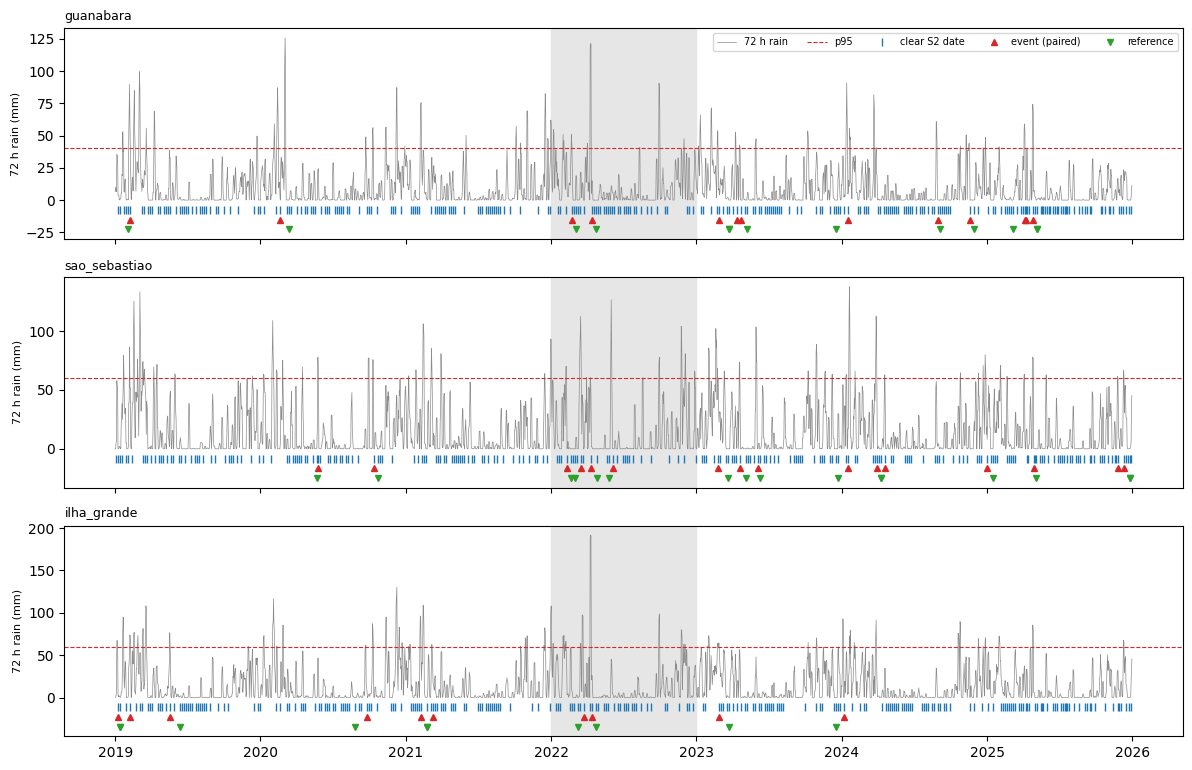

[11:36:52Z] saved /content/drive/MyDrive/Marine_Plastic_Detection/results/mvp4_feasibility/figures/mvp4_rain_clear_timeline.png (grey band = 2022 buffer)


In [12]:
# MVP4-11 | Timeline figure per site: 72 h rain, clear overpasses, paired events and references (saved PNG)
fig, axes = plt.subplots(len(SITES), 1, figsize=(12, 2.6 * len(SITES)), sharex=True)
for ax, s in zip(axes, SITES):
    r = load_rain(s); thr, clr, ev, dry, pairs = make_pairs(r, load_clear(s), P)
    r72 = r.rolling(3).sum().loc['2019':'2025']; y0 = -0.06 * float(np.nanmax(r72))
    ax.plot(r72.index, r72.values, lw=0.5, color='0.55', label='72 h rain')
    ax.axhline(thr, color='C3', lw=0.8, ls='--', label=f'p{P["rain_pct"]}')
    ax.plot(clr, np.full(len(clr), y0), '|', color='C0', ms=6, label='clear S2 date')
    if pairs:
        ax.plot([e for e, _ in pairs], np.full(len(pairs), 2 * y0), '^', color='C3', ms=4, label='event (paired)')
        ax.plot([f for _, f in pairs], np.full(len(pairs), 3 * y0), 'v', color='C2', ms=4, label='reference')
    ax.axvspan(pd.Timestamp('2022-01-01'), pd.Timestamp('2022-12-31'), color='0.9', zorder=0)
    ax.set_ylabel('72 h rain (mm)', fontsize=8); ax.set_title(s, loc='left', fontsize=9)
axes[0].legend(ncol=5, fontsize=7, loc='upper right')
fig.tight_layout(); path = f'{FIG}/mvp4_rain_clear_timeline.png'
fig.savefig(path, dpi=150); plt.show(); plt.close(fig); hb(f'saved {path} (grey band = 2022 buffer)')

In [13]:
# MVP4-12 | Feasibility verdict per site (rule fixed in MVP4-01) and log entry
S = read_json(f'{OUT}/mvp4_feasibility_summary.json')
V = {s: {'pairs_explore': v['n_pairs'].get('explore', 0), 'pairs_confirm': v['n_pairs'].get('confirm', 0),
         'storms_explore': v['n_storms'].get('explore', 0), 'storms_confirm': v['n_storms'].get('confirm', 0)}
     for s, v in S.items()}
for s, v in V.items():
    v['feasible'] = v['pairs_explore'] >= P['min_pairs'] and v['pairs_confirm'] >= P['min_pairs']
    v['c4_pop_2020'] = read_json(f'{OUT}/c4_population.json', {}).get(s, {}).get('pop_2020')
log_event('feasibility_verdict', {'rule': 'pairs >= min_pairs in explore AND confirm', 'params': P, 'verdict': V})
print(pd.DataFrame(V).T.to_string())

              pairs_explore pairs_confirm storms_explore storms_confirm feasible c4_pop_2020
guanabara                 2             9              2              8    False    10900899
sao_sebastiao             2            10              2             10    False      170135
ilha_grande               6             2              6              2    False      307739


In [14]:
# MVP4-13 | Session summary: compact view of the run log (keys and timestamps only)
for k, v in read_json(LOG, {}).items():
    print(f"{v.get('utc', ''):<26} {k}")

2026-09-24T11:30:16+00:00  env_20260924T113016
2026-09-24T11:30:16+00:00  D-M4-1
2026-09-24T11:30:17+00:00  catchment_guanabara
2026-09-24T11:30:17+00:00  catchment_sao_sebastiao
2026-09-24T11:30:18+00:00  catchment_ilha_grande
2026-09-24T11:30:23+00:00  C4_population
2026-09-24T11:36:52+00:00  feasibility_verdict


In [15]:
# MVP4-14 | Deviation D-M4-2: rain threshold p95 -> p90 (feasibility-driven, no FDI seen); recount pairs, storms, verdict
P2 = {**P, 'rain_pct': 90}
if 'D-M4-2' not in read_json(LOG, {}):
    log_event('D-M4-2', {
        'what': 'rain_pct 95 -> 90; all other parameters and the feasibility rule unchanged.',
        'why': 'Under p95 no site met the rule (explore pairs 2/2/6). clear_min kept at 0.7 because cloud '
               'adjacency is a known confounder (MVP-3 D6).',
        'data_seen': 'Rain/cloud metadata and pair counts only (MVP4-09/10). No reflectance, no FDI.',
        'params': P2})
V2 = {}
for s in SITES:
    thr, clr, ev, dry, pairs = make_pairs(load_rain(s), load_clear(s), P2)
    ev_d, refs = [e for e, _ in pairs], [f for _, f in pairs]
    npair, nstorm = per(ev_d), per(storm_starts(ev_d, P2['storm_gap_d']))
    V2[s] = {'r72_p90_mm': round(thr, 1),
             'pairs_explore': npair.get('explore', 0), 'pairs_confirm': npair.get('confirm', 0),
             'storms_explore': nstorm.get('explore', 0), 'storms_confirm': nstorm.get('confirm', 0),
             'refs_reused': len(refs) - len(set(refs))}
    V2[s]['feasible'] = V2[s]['pairs_explore'] >= P2['min_pairs'] and V2[s]['pairs_confirm'] >= P2['min_pairs']
    V2[s]['pairs'] = [{'event': str(e.date()), 'ref': str(f.date())} for e, f in pairs]
write_json(f'{OUT}/mvp4_feasibility_summary_p90.json', V2)
log_event('feasibility_verdict_p90', {'params': P2, 'verdict': {s: {k: v for k, v in d.items() if k != 'pairs'} for s, d in V2.items()}})
print(pd.DataFrame({s: {k: v for k, v in d.items() if k != 'pairs'} for s, d in V2.items()}).T.to_string())

              r72_p90_mm pairs_explore pairs_confirm storms_explore storms_confirm refs_reused feasible
guanabara           30.1             7            13              7             10           6     True
sao_sebastiao       47.2             9            17              9             15           8     True
ilha_grande         46.6            10             9             10              9           6     True


In [16]:
# MVP4-15 | Print catchment summaries saved by MVP4-02 (display fix)
for s in SITES:
    print(s, {k: v for k, v in read_json(LOG)[f'catchment_{s}'].items() if k != 'utc'})

guanabara {'area_km2': 4625.1, 'n_basins': 42, 'n_outlets': 14, 'top5_up_km2': [2125.1, 763, 315.2, 270.9, 256.4]}
sao_sebastiao {'area_km2': 1418.3, 'n_basins': 6, 'n_outlets': 4, 'top5_up_km2': [398.3, 391.8, 346.4, 283.1]}
ilha_grande {'area_km2': 2865.9, 'n_basins': 15, 'n_outlets': 11, 'top5_up_km2': [724.2, 498.6, 311.2, 281.6, 256.8]}


In [17]:
# MVP4-16 | Outlet check: coastal-composite flag, upstream area and centroid per outlet basin
rows = []
for s in SITES:
    fc = OUTLETS[s].map(lambda f: ee.Feature(None, {
        'HYBAS_ID': f.get('HYBAS_ID'), 'COAST': f.get('COAST'), 'UP_km2': f.get('UP_AREA'),
        'lon': f.geometry().centroid(100).coordinates().get(0),
        'lat': f.geometry().centroid(100).coordinates().get(1)})).getInfo()['features']
    rows += [{'site': s, **f['properties']} for f in fc]
OC = pd.DataFrame(rows).sort_values(['site', 'UP_km2'], ascending=[True, False])
OC[['lon', 'lat', 'UP_km2']] = OC[['lon', 'lat', 'UP_km2']].round(3)
write_csv(f'{OUT}/outlet_check.csv', OC); print(OC.drop(columns='HYBAS_ID').to_string(index=False))

         site  COAST  UP_km2     lat     lon
    guanabara      0  2125.1 -22.703 -42.966
    guanabara      0   763.0 -22.733 -43.268
    guanabara      1   315.2 -22.893 -43.236
    guanabara      0   270.9 -22.706 -43.232
    guanabara      1   256.4 -22.918 -43.011
    guanabara      0   220.4 -22.849 -43.401
    guanabara      0   194.6 -22.954 -43.370
    guanabara      0   161.2 -22.831 -43.014
    guanabara      0   135.8 -22.577 -43.085
    guanabara      1    80.6 -22.625 -43.051
    guanabara      1    43.6 -22.744 -43.021
    guanabara      1    33.9 -22.701 -43.156
    guanabara      1    14.3 -22.773 -43.289
    guanabara      1    12.3 -22.737 -43.242
  ilha_grande      0   724.2 -22.964 -44.543
  ilha_grande      1   498.6 -23.300 -44.720
  ilha_grande      1   311.2 -23.087 -44.710
  ilha_grande      1   281.6 -22.992 -44.240
  ilha_grande      1   256.8 -22.910 -43.956
  ilha_grande      1   223.8 -23.156 -44.237
  ilha_grande      0   187.6 -22.845 -44.446
  ilha_gra

In [18]:
# MVP4-17 | Stream mouths from HydroSHEDS 15ACC: sea-adjacent land cells with upstream area >= threshold, inside each site box
ACC = ee.Image('WWF/HydroSHEDS/15ACC').select('b1')
PRJ = ACC.projection()
CELL_KM2 = 0.197                     # approx. area of a 15" cell at ~23 S; upstream area = cells x CELL_KM2
MOUTH = dict(min_up_km2=10.0, dedup_m=1000.0)
sea = ACC.mask().Not()
coastal = sea.focalMax(1, 'square', 'pixels').reproject(PRJ).And(ACC.mask())
mouth_img = ACC.updateMask(coastal.And(ACC.gte(MOUTH['min_up_km2'] / CELL_KM2))).rename('acc')
def mouths_for(site):
    f = f'{OUT}/mouths_{site}.csv'
    if os.path.exists(f): return pd.read_csv(f)
    fc = mouth_img.sample(region=ee.Geometry.Rectangle(SITES[site]), projection=PRJ, geometries=True).getInfo()['features']
    df = pd.DataFrame([{'lon': g['geometry']['coordinates'][0], 'lat': g['geometry']['coordinates'][1],
                        'up_km2': g['properties']['acc'] * CELL_KM2} for g in fc])
    if len(df):
        df = df.sort_values('up_km2', ascending=False).reset_index(drop=True); keep = []
        for i, r in df.iterrows():                       # greedy de-duplication, small n
            if all(np.hypot((r.lon - df.lon[j]) * 102.5e3, (r.lat - df.lat[j]) * 111.0e3) > MOUTH['dedup_m'] for j in keep):
                keep.append(i)
        df = df.loc[keep].round({'lon': 4, 'lat': 4, 'up_km2': 1})
    write_csv(f, df); return df
MO = {s: mouths_for(s) for s in SITES}
log_event('mouths', {'params': {**MOUTH, 'cell_km2': CELL_KM2}, 'n': {s: len(d) for s, d in MO.items()}})
for s, d in MO.items():
    hb(f'{s}: {len(d)} mouths >= {MOUTH["min_up_km2"]} km2'); print(d.head(12).to_string(index=False))

[11:48:00Z] guanabara: 9 mouths >= 10.0 km2
     lon      lat  up_km2
-43.0354 -22.6938  2112.8
-43.2562 -22.7604   758.8
-43.2104 -22.7271   269.3
-43.2729 -22.7896   219.5
-43.0687 -22.8021   160.6
-43.1021 -22.6854   134.9
-43.2687 -22.8188    20.3
-43.0812 -22.6813    18.7
-43.0312 -22.7396    15.8
[11:48:00Z] sao_sebastiao: 10 mouths >= 10.0 km2
     lon      lat  up_km2
-45.7646 -23.7604    92.6
-45.8979 -23.7646    62.6
-45.8604 -23.7563    57.7
-45.3729 -23.8146    38.4
-45.6479 -23.7771    33.9
-45.6271 -23.7854    32.7
-45.7854 -23.7646    21.7
-45.5562 -23.7938    17.5
-45.6812 -23.7729    12.8
-45.4312 -23.8646    10.6
[11:48:00Z] ilha_grande: 16 mouths >= 10.0 km2
     lon      lat  up_km2
-44.5271 -23.0271   721.4
-44.3896 -22.9521   186.8
-44.3312 -22.9271   150.9
-44.0771 -22.9563   106.2
-44.6354 -23.2354    65.8
-44.2396 -23.0063    42.6
-44.3104 -22.9688    36.4
-44.4354 -22.9729    19.7
-44.2896 -23.1771    16.9
-44.1604 -23.0313    15.6
-44.6187 -23.0438    15.4
-4

In [21]:
# MVP4-18 | Supplementary outlets from OSM (Overpass): river/canal ends within 150 m of the OSM coastline, > 1 km from 15ACC mouths
import requests, hashlib
from shapely.geometry import LineString, Point
from shapely.strtree import STRtree
OSM = dict(types='river|canal', max_coast_m=150.0, dedup_m=1000.0)
to_xy = lambda lon, lat: ((np.asarray(lon, float) + 45.0) * 102.5e3, np.asarray(lat, float) * 111.0e3)
OVERPASS_URLS = ['https://overpass-api.de/api/interpreter',
                 'https://overpass.kumi.systems/api/interpreter',
                 'https://overpass.private.coffee/api/interpreter']
OVERPASS_HDR = {'User-Agent': 'MVP4-marine-debris-feasibility/1.0 (POLI-USP/IBGE research; Colab)',
                'Accept': 'application/json'}
def overpass(bb, body, tries=2):
    q = f'[out:json][timeout:180];({body.format(bbox=f"{bb[1]},{bb[0]},{bb[3]},{bb[2]}")});out geom;'
    last = None
    for url in OVERPASS_URLS:                      # main server first, then mirrors
        for k in range(tries):
            try:
                r = requests.post(url, data={'data': q}, headers=OVERPASS_HDR, timeout=240)
                if r.status_code == 200:
                    hb(f'overpass ok: {url.split("/")[2]}'); return r.json()['elements']
                last = f'{r.status_code} {url.split("/")[2]}'
            except requests.RequestException as e:
                last = f'{type(e).__name__} {url.split("/")[2]}'
            hb(f'overpass retry ({last})'); time.sleep(10 * (k + 1))
    raise RuntimeError(f'All Overpass endpoints failed; last: {last}')
def line(w):
    g = w.get('geometry', [])
    return LineString(np.column_stack(to_xy([p['lon'] for p in g], [p['lat'] for p in g]))) if len(g) > 1 else None
def osm_outlets(site):
    f, fr = f'{OUT}/osm_outlets_{site}.csv', f'{OUT}/osm_raw_{site}.json'
    if os.path.exists(f): return pd.read_csv(f)
    raw = read_json(fr)
    if raw is None:
        bb = SITES[site]
        raw = {'coast': overpass(bb, 'way["natural"="coastline"]({bbox});'),
               'water': overpass(bb, 'way["waterway"~"^(' + OSM['types'] + ')$"]({bbox});'),
               'fetched_utc': UTC().isoformat(timespec='seconds')}
        write_json(fr, raw)
    log_event(f'osm_raw_{site}', {'sha256': hashlib.sha256(open(fr, 'rb').read()).hexdigest(), 'fetched_utc': raw['fetched_utc'],
                                  'n_coast': len(raw['coast']), 'n_water': len(raw['water'])})
    coast = [l for l in map(line, raw['coast']) if l is not None]
    tree, rows = STRtree(coast), []
    for w in raw['water']:                                # loop over OSM ways (hundreds), not pixels
        g = w.get('geometry', [])
        for p in (g[:1] + g[-1:]) if len(g) > 1 else []:
            pt = Point(*map(float, to_xy(p['lon'], p['lat'])))
            d = pt.distance(coast[int(tree.nearest(pt))]) if coast else np.inf
            if d <= OSM['max_coast_m']:
                rows.append({'lon': p['lon'], 'lat': p['lat'], 'coast_m': round(d, 1),
                             'waterway': w['tags'].get('waterway'), 'name': w['tags'].get('name', '')})
    df, b = pd.DataFrame(rows), SITES[site]
    if len(df):
        df = df[df.lon.between(b[0], b[2]) & df.lat.between(b[1], b[3])].reset_index(drop=True)
        mx, my = to_xy(MO[site].lon.values, MO[site].lat.values); x, y = to_xy(df.lon.values, df.lat.values)
        dmin = np.hypot(x[:, None] - mx[None], y[:, None] - my[None]).min(axis=1) if len(mx) else np.full(len(df), np.inf)
        df = df[dmin > OSM['dedup_m']].assign(named=lambda d: d.name.ne('')).sort_values('named', ascending=False).reset_index(drop=True)
        xs, ys = to_xy(df.lon.values, df.lat.values); keep = []
        for i in range(len(df)):                          # greedy de-duplication, named outlets first
            if all(np.hypot(xs[i] - xs[j], ys[i] - ys[j]) > OSM['dedup_m'] for j in keep): keep.append(i)
        df = df.loc[keep].drop(columns='named').round({'lon': 4, 'lat': 4})
    write_csv(f, df); return df
OO = {}
for s in SITES:
    mem_guard('MVP4-18'); OO[s] = osm_outlets(s)
    hb(f'{s}: {len(OO[s])} supplementary OSM outlets'); print(OO[s].head(15).to_string(index=False))
log_event('osm_outlets', {'params': OSM, 'n': {s: len(d) for s, d in OO.items()}})

[12:08:28Z] guanabara: 23 supplementary OSM outlets
     lon      lat  coast_m waterway                name
-43.1100 -22.9127      0.0    river          Rio Icaraí
-43.2374 -22.8627    112.5    canal   Canal do Pinheiro
-43.2400 -22.8508      0.0    river           Rio Ramos
-43.1886 -22.7835      0.0    canal Canal dos Bancários
-43.2109 -22.8974      0.0    canal Desvio do Rio Joana
-43.2450 -22.7476      0.0    river          Rio Iguaçu
-43.0799 -22.8182      0.0    river         Rio Camarão
-43.1723 -22.9335    102.9    river         Rio Carioca
-43.0456 -22.6911      0.0    river       Canal de Magé
-43.0259 -22.7261      0.0    river          Rio Macacu
-43.0282 -22.7063      0.0    river          Rio Guaraí
-43.2734 -22.8104      0.0    river           Rio Irajá
-43.1758 -22.8239      0.0    river          Rio Jequiá
-43.1127 -22.6921      0.0    river           Rio Suruí
-43.1004 -22.8495      0.0    river                 NaN
[12:08:28Z] sao_sebastiao: 6 supplementary OSM outle

In [22]:
# MVP4-19 | Merge outlets: snap 15ACC mouths to the nearest OSM river/canal end within 2 km (OSM position+name, 15ACC area); add unmatched OSM ends
MERGE = dict(snap_m=2000.0, dedup_m=1000.0)
def osm_candidates(site):
    raw = read_json(f'{OUT}/osm_raw_{site}.json')
    coast = [l for l in map(line, raw['coast']) if l is not None]; tree, rows = STRtree(coast), []
    for w in raw['water']:
        g, t = w.get('geometry', []), w.get('tags', {})
        for p in (g[:1] + g[-1:]) if len(g) > 1 else []:
            pt = Point(*map(float, to_xy(p['lon'], p['lat'])))
            if coast and pt.distance(coast[int(tree.nearest(pt))]) <= OSM['max_coast_m']:
                rows.append({'lon': p['lon'], 'lat': p['lat'], 'waterway': t.get('waterway', ''), 'name': t.get('name', '')})
    b, df = SITES[site], pd.DataFrame(rows)
    return df[df.lon.between(b[0], b[2]) & df.lat.between(b[1], b[3])].drop_duplicates(['lon', 'lat']).reset_index(drop=True)
def merge_outlets(site):
    f = f'{OUT}/outlets_merged_{site}.csv'
    if os.path.exists(f): return pd.read_csv(f).fillna({'name': '', 'waterway': ''})
    C = osm_candidates(site); cx, cy = to_xy(C.lon.values, C.lat.values)
    used, out = np.zeros(len(C), bool), []
    for _, m in MO[site].sort_values('up_km2', ascending=False).iterrows():
        mx, my = to_xy(m.lon, m.lat); d = np.hypot(cx - mx, cy - my); d[used] = np.inf
        ok = np.where(d <= MERGE['snap_m'])[0]
        if len(ok):
            riv = ok[C.waterway.values[ok] == 'river']; pool = riv if len(riv) else ok
            j = pool[np.argmin(d[pool])]; used[j] = True
            out.append({'lon': C.lon[j], 'lat': C.lat[j], 'up_km2': m.up_km2, 'name': C.name[j],
                        'waterway': C.waterway[j], 'source': '15ACC+OSM', 'snap_m': round(float(d[j]))})
        else:
            out.append({'lon': m.lon, 'lat': m.lat, 'up_km2': m.up_km2, 'name': '', 'waterway': '',
                        'source': '15ACC', 'snap_m': np.nan})
    fx, fy = to_xy([o['lon'] for o in out], [o['lat'] for o in out])
    for i in sorted(np.where(~used)[0], key=lambda i: C.name[i] == ''):      # named OSM ends first
        if np.all(np.hypot(fx - cx[i], fy - cy[i]) > MERGE['dedup_m']):
            out.append({'lon': C.lon[i], 'lat': C.lat[i], 'up_km2': np.nan, 'name': C.name[i],
                        'waterway': C.waterway[i], 'source': 'OSM', 'snap_m': np.nan})
            fx, fy = np.append(fx, cx[i]), np.append(fy, cy[i])
    df = pd.DataFrame(out).round({'lon': 4, 'lat': 4}); write_csv(f, df); return df
OM = {}
for s in SITES:
    OM[s] = merge_outlets(s)
    hb(f"{s}: {len(OM[s])} outlets | {OM[s].source.value_counts().to_dict()}")
    print(OM[s].to_string(index=False))
log_event('outlets_merged', {'params': MERGE, 'n': {s: OM[s].source.value_counts().to_dict() for s in SITES}})
print('Named canals near Fundão present:', {k: bool(OM['guanabara'].name.str.contains(k).any()) for k in ('Cunha', 'Faria', 'Timbó')})

[12:11:25Z] guanabara: 29 outlets | {'OSM': 20, '15ACC+OSM': 8, '15ACC': 1}
     lon      lat  up_km2                name waterway    source  snap_m
-43.0364 -22.6922  2112.8                        river 15ACC+OSM   203.0
-43.2450 -22.7476   758.8          Rio Iguaçu    river 15ACC+OSM  1823.0
-43.2146 -22.7277   269.3         Rio Estrela    river 15ACC+OSM   433.0
-43.2728 -22.8028   219.5                        canal 15ACC+OSM  1464.0
-43.0687 -22.8021   160.6                                  15ACC     NaN
-43.1127 -22.6921   134.9           Rio Suruí    river 15ACC+OSM  1313.0
-43.2734 -22.8104    20.3           Rio Irajá    river 15ACC+OSM  1053.0
-43.0862 -22.6760    18.7                        river 15ACC+OSM   778.0
-43.0266 -22.7431    15.8      Rio Guaxindiba    river 15ACC+OSM   608.0
-43.1100 -22.9127     NaN          Rio Icaraí    river       OSM     NaN
-43.0259 -22.7261     NaN          Rio Macacu    river       OSM     NaN
-43.0282 -22.7063     NaN          Rio Guaraí   